# rocHPL trace → `predict_gpu.c` → coolant temperature at each GPU

You can measure a GPU's power and junction temperature. You can't measure the coolant reaching it. This notebook estimates the coolant from those two measurements, end to end:

1. **Reads the Score-P trace** of single-node rocHPL on Frontier, using Ampere.
2. **Writes one samples file per GPU**, in the format `predict_gpu.c` reads.
3. **Compiles and runs `predict_gpu.c`**, which writes one result file per GPU.
4. **Graphs the result.**
5. **Tests whether it catches a real coolant change**, using the water temperatures measured on the 3-cabinet run.

The idea in one line:

$$\text{coolant} = \text{measured junction} - \text{how far the GPU's own power has lifted it}$$

Power is never averaged: every sample goes in as measured, with its own timestamp. The junction sensor reads in 1 °C steps, so the difference above is smoothed over 30 s.

In [1]:
import io, re, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ampere import Ensemble, MetricConfig, MetricType, set_backend
set_backend('pandas')

ROOT = Path('.').resolve(); sys.path.insert(0, str(ROOT))
import frontier_model as fm

RUN = ROOT / 'rochpl_gpu'; RUN.mkdir(exist_ok=True)
PROGRAM = RUN / 'predict_gpu'
GPUS = [0, 1, 2, 3]
GPU_C = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
POWER_C, MEAS_C = '0.45', 'k'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

    _         _                   _       
   / \   _ __| | _____  _   _  __| | __ _ 
  / _ \ | '__| |/ / _ \| | | |/ _` |/ _` |
 / ___ \| |  |   < (_) | |_| | (_| | (_| |
/_/   \_\_|  |_|\_\___/ \__,_|\__,_|\__,_|
                                          
Client Version: 2026.02.02+40.gec39a6ec8

## Step 1: Power and junction temperature from the trace

Each MI250X package has an energy counter and a junction sensor. Ampere's `get_statistics_vectorized(...)['rate']` turns the energy counter into power over each counter interval. That's the finest power the counter gives; nothing is resampled.

In [2]:
configs = {re.compile(r".*rocm_smi.*energy.*"): MetricConfig(MetricType.CUMULATIVE, scale_factor=1e-6),    # uJ -> J
           re.compile(r".*rocm_smi.*temp.*"): MetricConfig(MetricType.INSTANTANEOUS, scale_factor=1e-3)}    # m°C -> °C
node = Ensemble.from_trace_paths([str(ROOT / 'data' / 'rochpl-frontier')], {"Node0": ["MPI Rank 0"]}, configs).runs[0].nodes[0]

TRACE = {}
for k, device in enumerate((0, 2, 4, 6)):
    energy = node.metrics[f"A2rocm_smi:::energy_count:device={device}"]
    t = np.asarray(energy.times.to_ndarray(), float)
    power = np.asarray(energy.get_statistics_vectorized(t[:-1], t[1:])['rate'], float)      # power[i] holds from t[i] to t[i + 1]
    sensor = node.metrics[f"A2rocm_smi:::temp_current:device={device}:sensor=1"]
    t_j = np.asarray(sensor.times.to_ndarray(), float); junction = np.asarray(sensor.values.to_ndarray(), float)
    keep = (t_j >= t[0]) & (t_j < t[-1])
    TRACE[k] = dict(t=t[:-1] - t[0], power=power, t_j=t_j[keep] - t[0], junction=junction[keep])
    print(f"GPU {k}: {len(power)} power samples (median gap {np.median(np.diff(t)) * 1e3:.1f} ms), {keep.sum()} junction readings (median gap {np.median(np.diff(t_j[keep])) * 1e3:.1f} ms) over {t[-1] - t[0]:.0f} s")

Loading Runs:   0%|          | 0/1 [00:00<?, ?it/s]

Loading Runs: 100%|██████████| 1/1 [00:01<00:00,  1.16s/it]

Loading Runs: 100%|██████████| 1/1 [00:01<00:00,  1.16s/it]

GPU 0: 21215 power samples (median gap 3.3 ms), 7284 junction readings (median gap 6.5 ms) over 82 s
GPU 1: 21215 power samples (median gap 3.3 ms), 7426 junction readings (median gap 6.5 ms) over 82 s
GPU 2: 21215 power samples (median gap 3.3 ms), 5832 junction readings (median gap 6.5 ms) over 82 s
GPU 3: 21215 power samples (median gap 3.3 ms), 6748 junction readings (median gap 6.5 ms) over 82 s


## Step 2: Write the samples files

Power samples and junction readings arrive at different moments, so each file merges them in time order. Each line is `power_W timestamp_s junction_C`. A line from the energy counter has `nan` for the junction, and a line from the sensor repeats the power holding at that moment.

In [3]:
for k in GPUS:
    d = TRACE[k]
    rows = pd.DataFrame({'power_W': np.r_[d['power'], d['power'][np.searchsorted(d['t'], d['t_j'], side='right') - 1]], 'timestamp_s': np.r_[d['t'], d['t_j']],
                         'junction_C': np.r_[np.full(len(d['power']), np.nan), d['junction']]}).sort_values('timestamp_s', kind='stable')
    with open(RUN / f'gpu{k}_samples.txt', 'w') as f:
        f.write("# Single-node rocHPL on Frontier, from Score-P. Columns: power_W timestamp_s junction_C\n")
        np.savetxt(f, rows.values, fmt='%.4f %.6f %.0f')
print(f"wrote {', '.join(f'gpu{k}_samples.txt' for k in GPUS)} in {RUN.name}/")
print(''.join(open(RUN / 'gpu0_samples.txt').readlines()[:6]))

wrote gpu0_samples.txt, gpu1_samples.txt, gpu2_samples.txt, gpu3_samples.txt in rochpl_gpu/
# Single-node rocHPL on Frontier, from Score-P. Columns: power_W timestamp_s junction_C
98.5390 0.000000 nan
98.5390 0.000000 40
85.4286 0.007460 nan
91.7102 0.013871 nan
85.8228 0.018847 nan



## Step 3: Compile and run `predict_gpu.c`

It uses the fitted numbers in `gpu_frontier.h`, which `./reproduce_constants.sh` regenerates from this same trace. These are the same commands you'd type in a terminal.

In [4]:
subprocess.run(['cc', '-O2', '-DPREDICT_GPU_MAIN', 'predict_gpu.c', '-lm', '-o', str(PROGRAM)], cwd=ROOT, check=True)
OUT = {}
for k in GPUS:
    with open(RUN / f'gpu{k}_coolant.csv', 'w') as f:
        subprocess.run([str(PROGRAM), str(k), str(RUN / f'gpu{k}_samples.txt')], stdout=f, check=True)
    OUT[k] = pd.read_csv(RUN / f'gpu{k}_coolant.csv')
print(f"wrote {', '.join(f'gpu{k}_coolant.csv' for k in GPUS)} in {RUN.name}/")
OUT[0].iloc[[0, 5000, 10000, 15000, -1]].round(3)

wrote gpu0_coolant.csv, gpu1_coolant.csv, gpu2_coolant.csv, gpu3_coolant.csv in rochpl_gpu/


,timestamp_s,power_W,junction_C,coolant_C,junction_model_C,water_out_C,flux_generated_W_cm2,flux_die_exit_W_cm2,flux_to_water_W_cm2
0,0.000,98.539,NaN,NaN,NaN,NaN,6.805,6.805,6.805
5000,16.172,232.197,NaN,34.410,42.059,34.848,16.036,10.474,6.741
10000,31.916,630.163,60.0,34.385,60.779,35.861,43.520,36.380,22.737
15000,46.572,752.863,NaN,34.370,63.224,36.411,51.993,37.889,31.434
28498,82.228,114.002,NaN,34.390,53.806,36.686,7.873,15.304,35.358


## Step 4: The estimated coolant

**How to read this figure.** Top: what was measured, each GPU's junction temperature (1 s averages, only so the lines stay readable). Bottom: what comes out, the estimated coolant at each GPU. The job starts around t = 15–19 s.

GPU 0: junction 39.7 -> 64.4 °C (+24.7); estimated coolant 34.5 -> 34.4 °C (-0.1)
GPU 1: junction 39.5 -> 58.8 °C (+19.3); estimated coolant 34.5 -> 35.1 °C (+0.5)
GPU 2: junction 36.1 -> 60.5 °C (+24.4); estimated coolant 30.7 -> 31.1 °C (+0.4)
GPU 3: junction 34.0 -> 52.9 °C (+18.9); estimated coolant 31.3 -> 30.3 °C (-1.0)


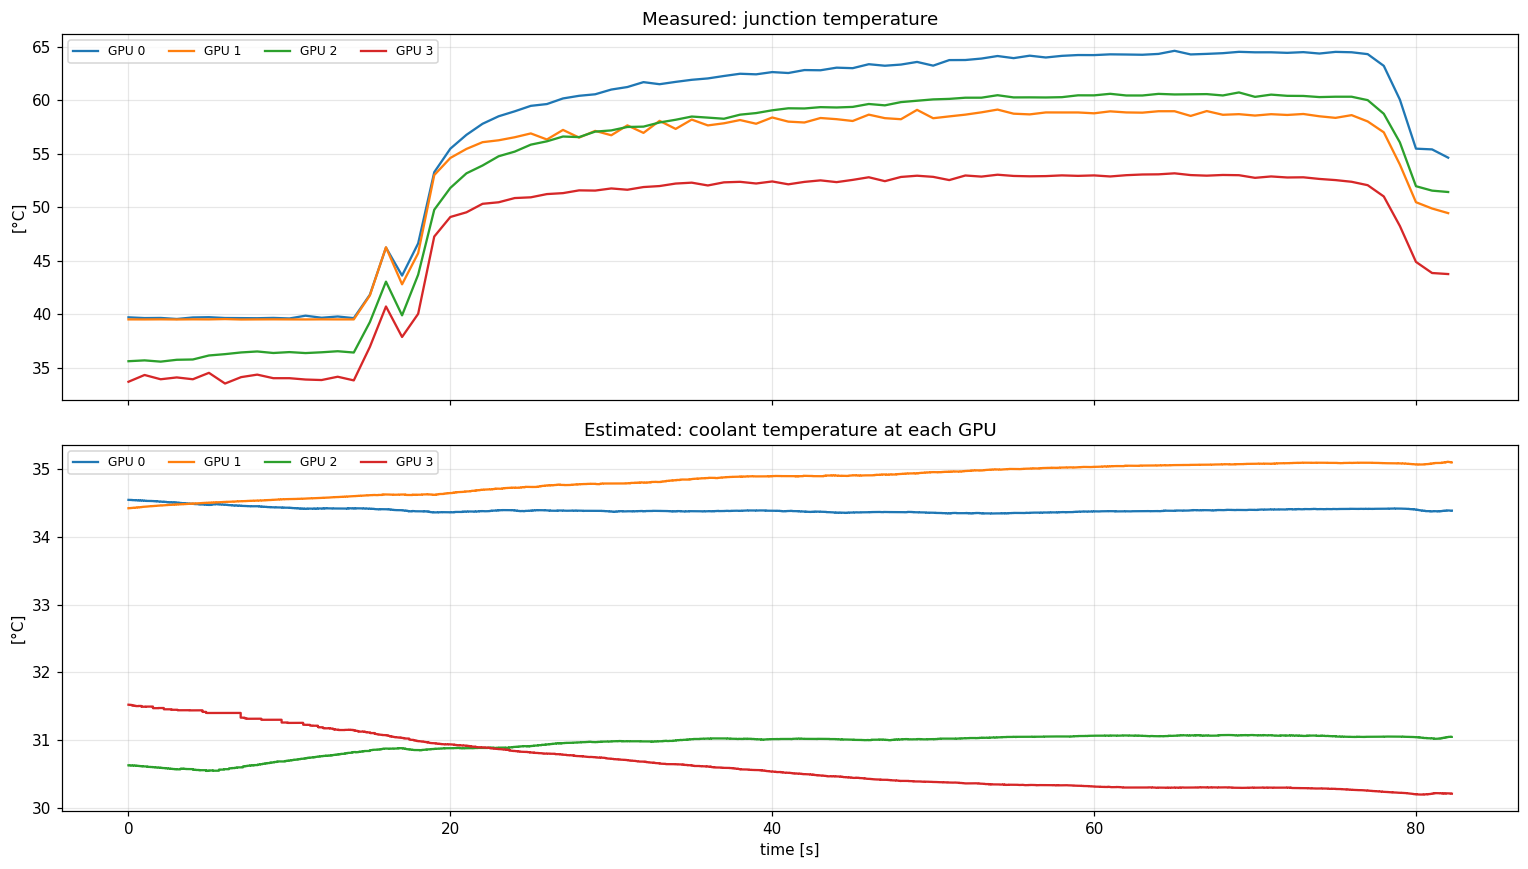

In [5]:
def fig_coolant():
    fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
    for k in GPUS:
        d = TRACE[k]; sec = np.floor(d['t_j']).astype(int)
        ax[0].plot(np.unique(sec), pd.Series(d['junction']).groupby(sec).mean(), color=GPU_C[k], lw=1.5, label=f'GPU {k}')
        ax[1].plot(OUT[k].timestamp_s, OUT[k].coolant_C, color=GPU_C[k], lw=1.5, label=f'GPU {k}')
    ax[0].set(ylabel='[°C]', title='Measured: junction temperature'); ax[0].legend(fontsize=8, ncol=4)
    ax[1].set(xlabel='time [s]', ylabel='[°C]', title='Estimated: coolant temperature at each GPU'); ax[1].legend(fontsize=8, ncol=4)
    fig.tight_layout(); fig.savefig(ROOT / 'figures' / 'rochpl_gpu_coolant.png', bbox_inches='tight')

fig_coolant()
for k in GPUS:
    o, d = OUT[k], TRACE[k]; t = o.timestamp_s
    j = lambda a, b: d['junction'][(d['t_j'] > a) & (d['t_j'] < b)].mean()
    print(f"GPU {k}: junction {j(0, 14):.1f} -> {j(60, 75):.1f} °C (+{j(60, 75) - j(0, 14):.1f}); estimated coolant {o.coolant_C[t < 14].mean():.1f} -> {o.coolant_C[(t > 60) & (t < 75)].mean():.1f} °C ({o.coolant_C[(t > 60) & (t < 75)].mean() - o.coolant_C[t < 14].mean():+.1f})")

**What this shows.**

* **The junctions rise by 19–25 °C, but the estimated coolant barely moves.** Each GPU's estimate shifts by 1 °C or less. That's what should happen: this job ran on one node, which adds very little heat to the coolant shared with the rest of its cabinets. So nearly all of the junction's rise gets correctly attributed to the GPU's own power.
* **Those shifts of up to 1 °C are a rough measure of the method's error.** GPU 3 drifts down by 1.0 °C and GPU 1 up by 0.5 °C, and real coolant wouldn't move in opposite directions by that much here. The first 30 s or so also lean on the first rounded sensor reading, because the smoothing has to start somewhere. So don't read much into changes under about 1 °C.
* **The GPUs sit at different levels:** about 34–35 °C for GPUs 0 and 1, and 30–31 °C for GPUs 2 and 3. Coolant flowing through the GPUs in series would produce differences like this, but this data can't confirm it, and differences in paste or plate contact would look the same. Trust changes over time more than the level.

**A caution on this check:** the fitted numbers came from this same trace, so a flat result is expected. It shows the method isn't broken, not that it's right. Step 5 is the harder test.

### Heat flux, and the model against the sensor

Heat flux needs no coolant measurement, because it depends only on how far the layers are lifted. **Left:** half a second at full load on GPU 0, showing the heat the chip makes (grey), the heat leaving the die (blue), and the heat entering the water (orange). **Right:** the same stretch of time, showing whether the model follows the junction: the black dots are the sensor, and the line is the estimated coolant plus the modelled lift.

at full load, t = 50-53 s: made by the chip swings by 7.89 W/cm² (std), leaving the die 2.15, entering the water 0.252


GPU 0: modelled junction vs sensor, RMS 0.74 °C
GPU 1: modelled junction vs sensor, RMS 0.78 °C
GPU 2: modelled junction vs sensor, RMS 0.79 °C
GPU 3: modelled junction vs sensor, RMS 0.92 °C


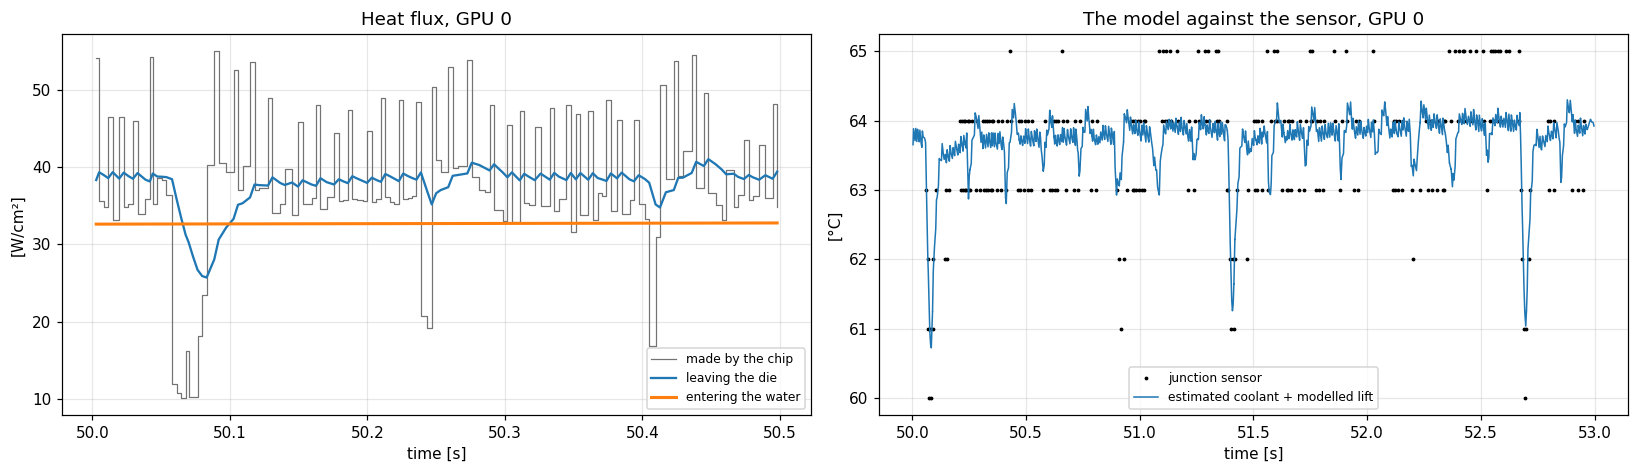

In [6]:
def fig_flux():
    k = 0; o, d = OUT[k], TRACE[k]
    A = fm.A_DIE_CM2; m = (o.timestamp_s >= 50) & (o.timestamp_s < 53)
    z = (o.timestamp_s >= 50) & (o.timestamp_s < 50.5)
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.4))
    a = ax[0]
    a.step(o.timestamp_s[z], o.flux_generated_W_cm2[z], where='post', color=POWER_C, lw=0.8, label='made by the chip')
    a.plot(o.timestamp_s[z], o.flux_die_exit_W_cm2[z], color='tab:blue', lw=1.5, label='leaving the die')
    a.plot(o.timestamp_s[z], o.flux_to_water_W_cm2[z], color='tab:orange', lw=2, label='entering the water')
    a.set(xlabel='time [s]', ylabel='[W/cm²]', title='Heat flux, GPU 0'); a.legend(fontsize=8)
    a = ax[1]; w = (d['t_j'] >= 50) & (d['t_j'] < 53)
    a.plot(d['t_j'][w], d['junction'][w], '.', color=MEAS_C, ms=3, label='junction sensor')
    a.plot(o.timestamp_s[m], o.junction_model_C[m], color='tab:blue', lw=1, label='estimated coolant + modelled lift')
    a.set(xlabel='time [s]', ylabel='[°C]', title='The model against the sensor, GPU 0'); a.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(ROOT / 'figures' / 'rochpl_gpu_flux.png', bbox_inches='tight')
    print(f"at full load, t = 50-53 s: made by the chip swings by {o.flux_generated_W_cm2[m].std():.2f} W/cm² (std), leaving the die {o.flux_die_exit_W_cm2[m].std():.2f}, entering the water {o.flux_to_water_W_cm2[m].std():.3f}")
    for k in GPUS:
        ok = OUT[k].junction_C.notna() & (OUT[k].timestamp_s > 5)
        print(f"GPU {k}: modelled junction vs sensor, RMS {np.sqrt(np.mean((OUT[k].junction_model_C[ok] - OUT[k].junction_C[ok]) ** 2)):.2f} °C")

fig_flux()

**What this shows.**

* **Left:** the chip's heat swings hard (7.9 W/cm², as a standard deviation over 3 s), the heat leaving the die swings much less (2.2), and the heat entering the water is almost flat (0.25, mostly slow drift). The layers absorb the fast swings.
* **Right:** the model follows the sensor, including the sharp dips at each stall in the job. Across the run it's off by 0.74–0.92 °C RMS, and the sensor's 1 °C steps account for part of that.

## Step 5: Does it catch a real coolant change?

The trace can't answer this: one node hardly warms the coolant shared with the rest of its cabinets. So here's a test with a known answer.

* **The true coolant** is the water temperature measured on the 3-cabinet HPL run (`3Cab_POW.txt`), including its roughly 5 °C rise after the job starts, plus GPU 0's offset.
* **The GPU's power** is that run's measured node power, divided among 4 GPUs.
* **The junction sensor** is simulated from those two, then given the real sensor's flaws: noise, and rounding to 1 °C steps.

`predict_gpu.c` sees only the power and the rounded junction, and has to recover the water temperature. This is a simulation: it tests the method, not real hardware.

power correct         : typical error 0.51 °C, worst 2.70 °C; peak 38.1 °C at t = 372 s (true 38.8 °C at 327 s)
power reads 5 % low   : typical error 0.98 °C, worst 2.41 °C; peak 39.3 °C at t = 372 s (true 38.8 °C at 327 s)
power reads 10 % high : typical error 1.74 °C, worst 4.93 °C; peak 35.6 °C at t = 372 s (true 38.8 °C at 327 s)


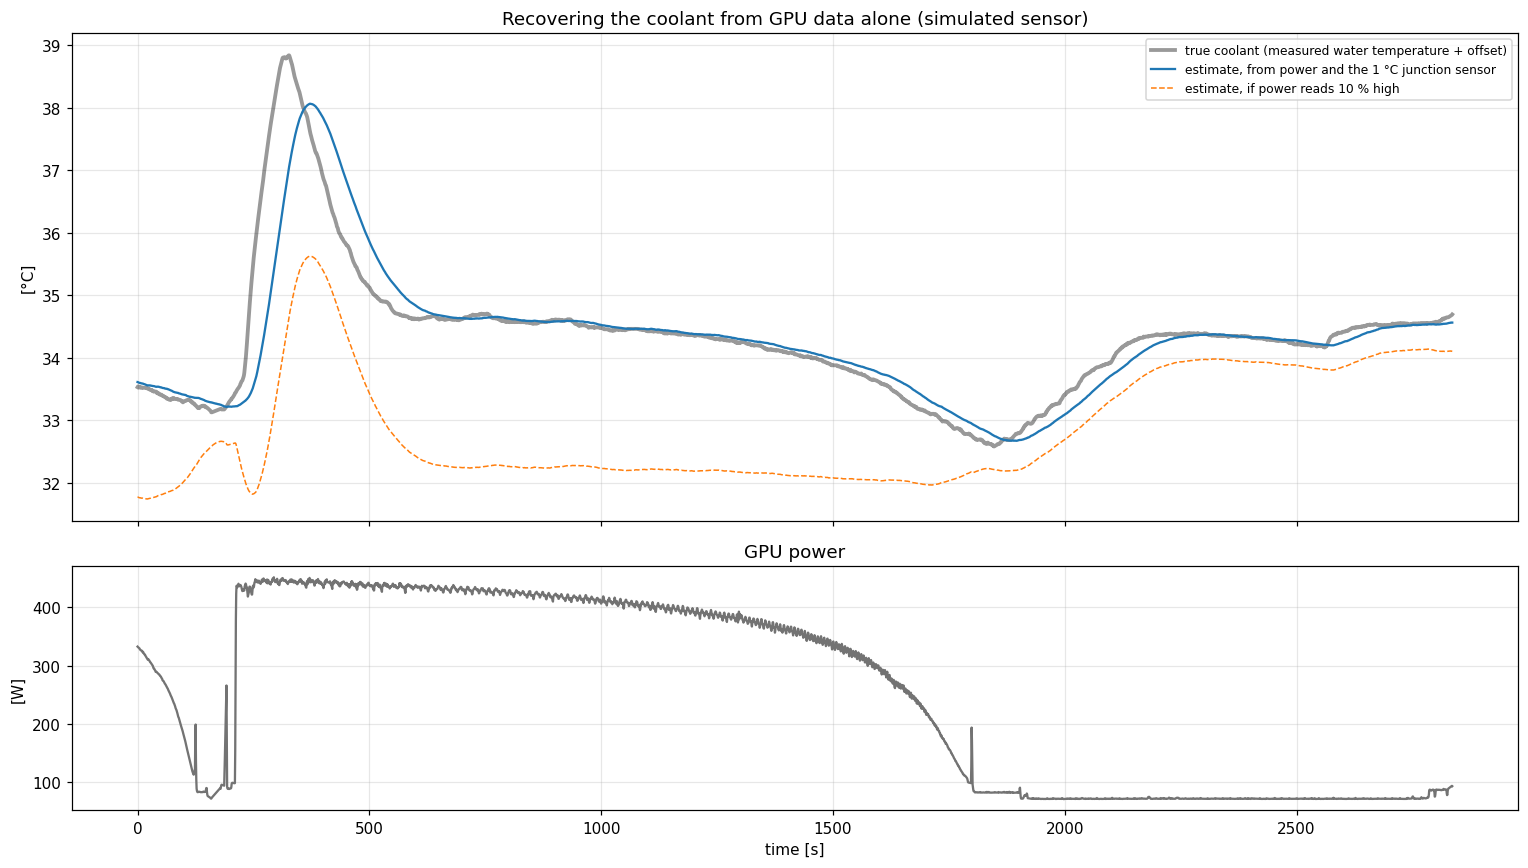

In [7]:
M = fm.load_model()
raw = pd.read_csv(ROOT / '3Cab_POW.txt', sep=r'\s+', skiprows=11)
t_raw = (pd.to_datetime(raw.TS) - pd.to_datetime(raw.TS.iloc[0])).dt.total_seconds().to_numpy()
col = lambda c: raw[c].to_numpy(float)
DT = 0.007                                       # a reading every 7 ms, like the real sensor
t_s = np.arange(0, np.floor(t_raw[-1]), DT)
true_coolant = np.interp(t_s, t_raw, np.mean([col(f'LIT_C{i}') for i in (1, 2, 3)], 0)) + M['jnet'][0]['dTc']
gpu_W = np.interp(t_s, t_raw, fm.package_from_node(M, col('RFNP_C1') / fm.N_NODES))
rng = np.random.default_rng(0)
jn = M['jnet'][0]
sensor_C = np.round(fm.junction_response(gpu_W, true_coolant, jn['R'], jn['C'], dt=DT)['T'][0] + rng.normal(0, 0.4, len(t_s)))

def estimate(power_W, label):
    f = RUN / f'test_{label}_samples.txt'
    np.savetxt(f, np.c_[power_W, t_s, sensor_C], fmt='%.3f %.5f %.0f')
    r = subprocess.run([str(PROGRAM), '0', str(f)], capture_output=True, text=True, check=True)
    return pd.read_csv(io.StringIO(r.stdout)).coolant_C.to_numpy()

TEST = {'power correct': estimate(gpu_W, 'correct'), 'power reads 5 % low': estimate(0.95 * gpu_W, 'low'), 'power reads 10 % high': estimate(1.10 * gpu_W, 'high')}
late = t_s > 120; win = (t_s > 200) & (t_s < 600)
for name, e in TEST.items():
    d = e - true_coolant
    print(f"{name:22s}: typical error {np.sqrt(np.mean(d[late] ** 2)):.2f} °C, worst {np.abs(d[late]).max():.2f} °C; peak {e[win].max():.1f} °C at t = {t_s[win][np.argmax(e[win])]:.0f} s (true {true_coolant[win].max():.1f} °C at {t_s[win][np.argmax(true_coolant[win])]:.0f} s)")

def fig_test():
    fig, ax = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    dec = slice(None, None, 100)
    a = ax[0]
    a.plot(t_s[dec], true_coolant[dec], color=MEAS_C, lw=2.5, alpha=0.4, label='true coolant (measured water temperature + offset)')
    a.plot(t_s[dec], TEST['power correct'][dec], color='tab:blue', lw=1.5, label='estimate, from power and the 1 °C junction sensor')
    a.plot(t_s[dec], TEST['power reads 10 % high'][dec], color='tab:orange', lw=1, ls='--', label='estimate, if power reads 10 % high')
    a.set(ylabel='[°C]', title='Recovering the coolant from GPU data alone (simulated sensor)'); a.legend(fontsize=8)
    a = ax[1]; a.plot(t_s[dec], gpu_W[dec], color=POWER_C, lw=1.5); a.set(xlabel='time [s]', ylabel='[W]', title='GPU power')
    fig.tight_layout(); fig.savefig(ROOT / 'figures' / 'rochpl_gpu_coolant_test.png', bbox_inches='tight')

fig_test()

**What this shows.**

1. **It catches the coolant rise after a job starts.** The estimate reaches 38.1 °C against the true 38.8 °C, from nothing but GPU power and a junction sensor in 1 °C steps.
2. **It's late.** The true peak is at 327 s and the estimate's is at 372 s, about 45 s behind. That comes from the 30 s smoothing plus the time heat takes to pass through the layers. During that fast rise it can be up to 2.7 °C off. Once things are changing slowly, the error is small: 0.51 °C typical over the whole run.
3. **It depends on accurate power.** If power reads 10 % high, the typical error becomes 1.74 °C and the peak reads 35.6 °C, because too much of the junction's temperature gets blamed on the GPU's own heating. The shape of the rise survives, but the size doesn't. If you doubt the power calibration, compare the estimate with itself over time, rather than trusting its level.

**What this doesn't show.** The sensor here is simulated, and the junction was generated by this same type of model, so this is close to a best case. Real coolant has never been compared with this estimate. That needs a Score-P trace from a node inside a cooling group, taken while that group's coolant telemetry is being logged.

**What a GPU can't tell you.** This is the coolant at that GPU only. The valve's flow, the cabinet outlets and the building water don't show up in a GPU's own data.